# Notebook 02 — Preparación y modelado de datos (Fase 3)

**Qué hace este notebook:** limpia el dataset original, trata los valores atípicos, selecciona variables, define dimensiones y métricas y deja listo un archivo limpio (`data/processed/lineas_limpias.parquet`) que usan los notebooks 03, 04 y 05 y el dashboard.

**Principio de trabajo:** cada regla de limpieza se justifica por una razón de negocio y se registra cuántas filas elimina, para que cualquiera pueda auditar la decisión.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Carga y renombrado

Se renombran las columnas a `snake_case` para evitar el espacio de `Customer ID` y facilitar el código.

In [2]:
raw = pd.read_csv(RAW, parse_dates=['InvoiceDate'],
                  dtype={'Invoice': 'string', 'StockCode': 'string'})
df = raw.rename(columns={
    'Invoice': 'factura', 'StockCode': 'codigo', 'Description': 'descripcion',
    'Quantity': 'cantidad', 'InvoiceDate': 'fecha_hora', 'Price': 'precio',
    'Customer ID': 'cliente_id', 'Country': 'pais'})
df['es_cancelacion'] = df['factura'].str.startswith('C')
print(f'{len(df):,} filas cargadas')
df.head(3)

1,067,371 filas cargadas


,factura,codigo,descripcion,cantidad,fecha_hora,precio,cliente_id,pais,es_cancelacion
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False


## 2. Reglas de limpieza (en este orden)

| # | Regla | Por qué |
|---|---|---|
| R1 | Eliminar líneas **duplicadas exactas** | Mismo pedido, producto, cantidad, precio y hora: son registros repetidos y inflan las ventas |
| R2 | Eliminar **códigos que no son productos** (envío, comisiones, ajustes, pruebas) | No son ventas de mercancía; distorsionan precio medio y ticket |
| R3 | Eliminar **precio ≤ 0** | Son ajustes contables o regalos sin valor de venta |
| R4 | Eliminar **cantidad ≤ 0 que no sea cancelación** | Mercancía dañada o ajustes de inventario, no ventas ni devoluciones de clientes |

**Lo que NO se elimina:** las **cancelaciones** (factura con `C`): son devoluciones reales y las necesitamos para medir la tasa de devolución. Tampoco se eliminan las líneas **sin cliente** (≈15 % del ingreso): sirven para los KPIs de ventas, solo se excluyen de los análisis *por cliente*.

In [3]:
patron_producto = r'^\d{5}|^DCGS|^gift_'
registro = [{'regla': 'Dataset original', 'filas_restantes': len(df), 'filas_eliminadas': 0}]

def aplicar(nombre, mascara_conservar, datos):
    out = datos[mascara_conservar]
    registro.append({'regla': nombre, 'filas_restantes': len(out),
                     'filas_eliminadas': len(datos) - len(out)})
    return out

d1 = aplicar('R1 duplicados exactos', ~df.duplicated(), df)
d2 = aplicar('R2 codigos que no son producto', d1['codigo'].str.match(patron_producto), d1)
d3 = aplicar('R3 precio <= 0', d2['precio'] > 0, d2)
d4 = aplicar('R4 cantidad <= 0 sin ser cancelacion',
             (d3['cantidad'] > 0) | d3['es_cancelacion'], d3)

reglas = pd.DataFrame(registro)
reglas['% eliminado del original'] = (reglas['filas_eliminadas'] / len(df) * 100).round(2)
reglas

,regla,filas_restantes,filas_eliminadas,% eliminado del original
0,Dataset original,1067371,0,0.00
1,R1 duplicados exactos,1033036,34335,3.22
2,R2 codigos que no son producto,1027313,5723,0.54
3,R3 precio <= 0,1021330,5983,0.56
4,R4 cantidad <= 0 sin ser cancelacion,1021330,0,0.00


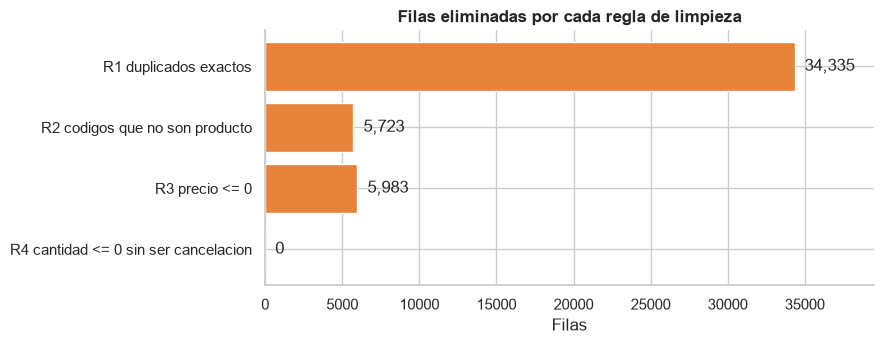

Filas finales: 1,021,330 (95.7% del original)


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
r = reglas.iloc[1:]
ax.barh(r['regla'][::-1], r['filas_eliminadas'][::-1], color=NARANJA)
for i, v in enumerate(r['filas_eliminadas'][::-1]):
    ax.text(v, i, f'  {v:,}', va='center')
ax.set_title('Filas eliminadas por cada regla de limpieza')
ax.set_xlabel('Filas')
ax.set_xlim(0, r['filas_eliminadas'].max() * 1.15)
plt.tight_layout()
plt.savefig(FIG / '02_limpieza_filas_por_regla.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Filas finales: {len(d4):,} ({len(d4)/len(df):.1%} del original)')

**Lectura de la tabla de reglas.**
- R1 (duplicados) es la regla que más elimina: **34.335 líneas (3,2 % del original)**.
- R2 y R3 eliminan 5.723 y 5.983 líneas (≈ 0,5 % cada una).
- **R4 eliminó 0 filas adicionales:** las líneas con cantidad ≤ 0 que no eran cancelaciones ya tenían precio 0, así que R3 las había quitado. Se deja la regla en el código como *verificación*: confirma que no queda ninguna cantidad negativa fuera de las devoluciones.
- Quedan **1.021.330 líneas (95,7 % del original)**: se limpió poco, lo que indica que la fuente es de buena calidad.

## 3. Valores faltantes tras la limpieza

Quedan dos variables con faltantes: `descripcion` y `cliente_id`. Se tratan con criterio distinto porque su impacto es distinto.

In [5]:
limpio = d4.copy()
faltantes = limpio[['descripcion', 'cliente_id']].isna().sum().to_frame('nulos')
faltantes['% de lineas'] = (faltantes['nulos'] / len(limpio) * 100).round(2)
faltantes

,nulos,% de lineas
descripcion,0,0.00
cliente_id,227167,22.24


In [6]:
# descripcion: se unifica por codigo (la mas frecuente) y se normaliza el texto
desc_modal = (limpio.dropna(subset=['descripcion'])
              .groupby('codigo')['descripcion']
              .agg(lambda s: s.str.strip().str.upper().mode().iloc[0]))
limpio['descripcion'] = limpio['codigo'].map(desc_modal)
print('Descripciones aun nulas:', limpio['descripcion'].isna().sum())

# cliente_id: NO se imputa (inventar un cliente seria falso). Se marca como invitado.
limpio['es_invitado'] = limpio['cliente_id'].isna()
print(f'Lineas de invitados (sin cliente): {limpio["es_invitado"].mean():.1%}')

Descripciones aun nulas: 0
Lineas de invitados (sin cliente): 22.2%


## 4. Valores atípicos

En ventas mayoristas la cola derecha es larga **por naturaleza** (un pedido de 10.000 unidades puede ser legítimo). Por eso:
- se mide el atípico sobre el **logaritmo** del importe (si no, casi todo lo grande parecería atípico);
- se **revisan a mano** los extremos antes de decidir si se eliminan.

In [7]:
limpio['importe'] = limpio['cantidad'] * limpio['precio']
ventas = limpio[~limpio['es_cancelacion']].copy()
ventas['log_importe'] = np.log10(ventas['importe'])

q1, q3 = ventas['log_importe'].quantile([.25, .75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
ventas['atipico_iqr'] = (ventas['log_importe'] < lim_inf) | (ventas['log_importe'] > lim_sup)
z = stats.zscore(ventas['log_importe'])
ventas['atipico_z3'] = np.abs(z) > 3

print(f'Limites IQR sobre log10(importe): [{lim_inf:.2f}, {lim_sup:.2f}]  ->  £{10**lim_inf:,.2f} a £{10**lim_sup:,.0f}')
print(f'Atipicos IQR: {ventas["atipico_iqr"].sum():,} lineas ({ventas["atipico_iqr"].mean():.2%})')
print(f'Atipicos |z|>3: {ventas["atipico_z3"].sum():,} lineas ({ventas["atipico_z3"].mean():.2%})')

Limites IQR sobre log10(importe): [-0.33, 2.20]  ->  £0.47 a £157
Atipicos IQR: 19,454 lineas (1.94%)
Atipicos |z|>3: 5,335 lineas (0.53%)


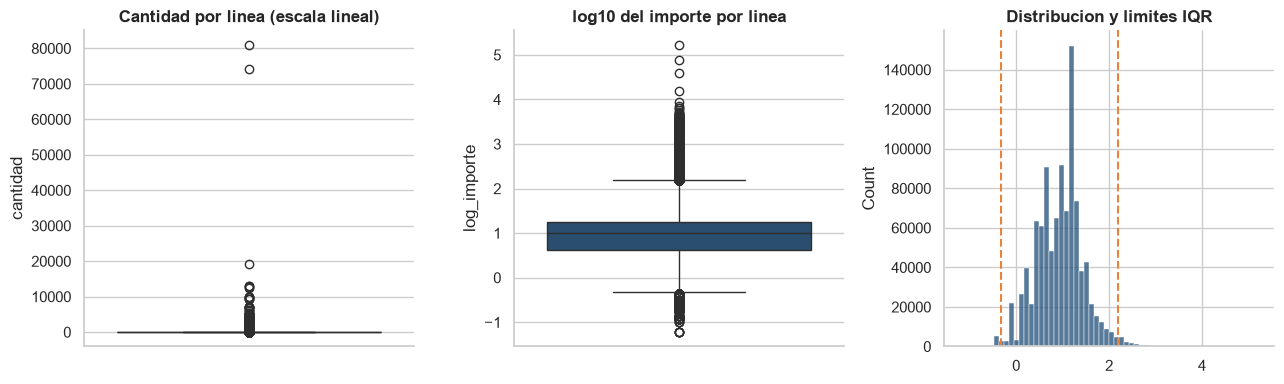

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
sns.boxplot(y=ventas['cantidad'], ax=axs[0], color=AZUL)
axs[0].set_title('Cantidad por linea (escala lineal)')
sns.boxplot(y=ventas['log_importe'], ax=axs[1], color=AZUL)
axs[1].set_title('log10 del importe por linea')
sns.histplot(ventas['log_importe'], bins=60, color=AZUL, ax=axs[2])
axs[2].axvline(lim_inf, color=NARANJA, ls='--'); axs[2].axvline(lim_sup, color=NARANJA, ls='--')
axs[2].set_title('Distribucion y limites IQR')
for a in axs: a.set_xlabel('')
plt.tight_layout()
plt.savefig(FIG / '02_outliers_importe.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Revision manual de los 10 importes mas grandes
cols = ['factura', 'codigo', 'descripcion', 'cantidad', 'precio', 'importe', 'cliente_id', 'pais', 'fecha_hora']
ventas.sort_values('importe', ascending=False)[cols].head(10)

,factura,codigo,descripcion,cantidad,precio,importe,cliente_id,pais,fecha_hora
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60","16,446.00",United Kingdom,2011-12-09 09:15:00
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60","12,346.00",United Kingdom,2011-01-18 10:01:00
748132,556444,22502,PICNIC BASKET WICKER SMALL,60,649.50,"38,970.00","15,098.00",United Kingdom,2011-06-10 15:28:00
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,818.40","15,838.00",United Kingdom,2010-11-04 11:36:00
228042,511465,15044A,PINK PAPER PARASOL,3500,2.55,"8,925.00","18,008.00",United Kingdom,2010-06-08 12:59:00
873786,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72","17,450.00",United Kingdom,2011-09-20 11:05:00
578172,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40","15,749.00",United Kingdom,2011-01-11 12:55:00
686007,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40","15,749.00",United Kingdom,2011-04-18 13:20:00
461644,533027,22086,PAPER CHAIN KIT 50'S CHRISTMAS,835,6.95,"5,803.25",NaN,United Kingdom,2010-11-15 16:02:00
379875,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,"5,179.20","15,838.00",United Kingdom,2010-10-08 10:10:00


In [10]:
# Los dos pedidos gigantes (74.215 y 80.995 unidades): fueron cancelados minutos despues?
gigantes = limpio[limpio['cantidad'].abs() >= 70000][cols + ['es_cancelacion']]
gigantes.sort_values('fecha_hora')

,factura,codigo,descripcion,cantidad,precio,importe,cliente_id,pais,fecha_hora,es_cancelacion
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60","12,346.00",United Kingdom,2011-01-18 10:01:00,False
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"-77,183.60","12,346.00",United Kingdom,2011-01-18 10:17:00,True
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60","16,446.00",United Kingdom,2011-12-09 09:15:00,False
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"-168,469.60","16,446.00",United Kingdom,2011-12-09 09:27:00,True


**Qué se decidió y por qué.**

- Con el criterio IQR sobre el log del importe, **19.454 líneas (1,9 %)** quedan fuera del rango "normal" (£0,47 a £157 por línea). Con |z| > 3 son 5.335 (0,5 %). Casi todas son pedidos mayoristas legítimos (miles de unidades de un producto barato), así que **no se eliminan: se marcan con `atipico_iqr`** y las pruebas estadísticas usan métodos robustos (Mann-Whitney, log).
- Los **dos casos más extremos sí se eliminan (R5)**: un pedido de 74.215 unidades (£77.184) y otro de 80.995 unidades (£168.470) fueron **cancelados 16 y 12 minutos después** de crearse, siempre por el mismo cliente y producto. Parecen errores de captura. Si se dejaran, sumarían £245.653 a las ventas brutas **y** a las devoluciones, inflando artificialmente la tasa de devolución (de 2,4 % a 3,6 %) sin cambiar los ingresos netos.
- Se eliminan **4 líneas** (2 pedidos + 2 cancelaciones); los ingresos netos no cambian.

In [11]:
# Decision R5: se eliminan SOLO los 2 pedidos gigantes y sus 2 cancelaciones (4 lineas)
n_antes = len(limpio)
limpio = limpio[limpio['cantidad'].abs() < 70000]
registro.append({'regla': 'R5 pedidos gigantes cancelados a los minutos',
                 'filas_restantes': len(limpio), 'filas_eliminadas': n_antes - len(limpio)})
print(f'Filas eliminadas por R5: {n_antes - len(limpio)} | filas restantes: {len(limpio):,}')
pd.DataFrame(registro)

Filas eliminadas por R5: 4 | filas restantes: 1,021,326


,regla,filas_restantes,filas_eliminadas
0,Dataset original,1067371,0
1,R1 duplicados exactos,1033036,34335
2,R2 codigos que no son producto,1027313,5723
3,R3 precio <= 0,1021330,5983
4,R4 cantidad <= 0 sin ser cancelacion,1021330,0
5,R5 pedidos gigantes cancelados a los minutos,1021326,4
